# 48 · 답변만 학습하는 SFT와 LoRA

과일의 색을 그대로 답하던 작은 모델에게 **다음 색을 답하는 새 지시**를 가르칩니다. prompt를 정답처럼 외우는 손실과 답변을 학습하는 손실을 구분하고, 모든 가중치를 고칠지 작은 저랭크 변화만 고칠지 비교합니다.

- 준비물: [44 token shift](44_tokenization.ipynb), [45 전체 decoder 미분](45_decoder_gpt.ipynb), [46 자유 생성](46_generation_kv_cache.ipynb), [13 계산 경로](../02_연결/13_autodiff.ipynb)입니다.
- 순서: ① 답변 손실 mask → ② 저랭크 변화 → ③ 고정 경로와 전체 미분 → ④ 실제 사전학습·세 방식 적응 → ⑤ merge·생성·기존 과제 변화입니다.
- 범위: 이 notebook 안에서 작은 token decoder를 처음부터 학습합니다. 외부 pretrained·API는 사용하지 않습니다. LoRA는 attention의 Wq/Wv 두 행렬에만 적용합니다.

> **용어** · **SFT(supervised fine-tuning)**는 prompt에 대응하는 정답 답변으로 모델을 추가 학습하는 것입니다. **frozen**은 해당 파라미터를 갱신하지 않는다는 뜻입니다. **LoRA**는 고정 행렬에 저랭크 행렬곱의 변화량을 더해 학습하는 방법입니다. **merge**는 학습된 변화량을 고정 행렬의 사본에 합쳐 추론하는 절차입니다.

### 읽는 법

| 표시 | 확인할 것 |
|---|---|
| 🔑 핵심 | 손실 선택·미분·갱신 범위 |
| 🔍 확인 | 손계산·실험·한계 |
| 📎 참고 | 출처·범위·코드 |
| ✏️ 연습 | 한두 줄 직접 구성 |

**이 노트북에서 반드시 가져갈 세 가지**

1. prompt는 입력 조건이며 답변+EOS만 SFT 손실로 셉니다.
2. frozen 가중치도 입력 미분에는 필요합니다. LoRA의 A/B만 갱신한다는 말과 계산을 끊는 것은 다릅니다.
3. 학습 파라미터 수·새 과제 성능·기존 과제 유지·merge 동등성을 따로 검산합니다.

[그림 보조 코드](../../src/utils/sft_lora_plots.py) · [학습 경로](../../docs/CURRICULUM.md)

In [1]:
# 준비 셀: 이전 notebook 실행 상태를 사용하지 않습니다.
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.sft_lora_plots import (
    plot_response_mask,plot_lora_weights,plot_frozen_gradient,plot_trainable_budget,
    plot_merge_logits,plot_adaptation_learning,
)
setup_plots()

'Arial Unicode MS'

## 🔑 1. prompt를 읽되 답변 위치에서만 손실을 냅니다

**이 절에서 가져갈 것:** 첫 답변 token과 EOS를 정확히 선택하고 prompt의 logits 손실은0으로 둡니다.

prompt `[NEXT,fruit,color,SEP]`에 답변 `[next_color]`를 붙입니다. BOS를 앞에, EOS를 뒤에 붙인 전체열을 한 칸 이동합니다. SEP 입력 위치에서 첫 답변을 예측하고, 첫 답변 입력 위치에서 EOS를 예측합니다.

$$L_{SFT}=-\frac{\sum_{n,t}r_{nt}\log\pi_\theta(y_{nt}\mid I_{n,\le t})}{\sum_{n,t}r_{nt}}.$$

I,target,valid,response mask는 `(N,T)`입니다. response mask r의1은 **target이 답변 또는 EOS**인 위치입니다. prompt 길이가 P일 때 target 배열의 P번 위치부터 켭니다. 답변이 비어 있어도 EOS 하나를 학습합니다. 길이가 다른 답변은 유효 답변 token 수로 가중됩니다.

> **용어** · **response-only loss**는 prompt의 NLL을 제외하고 답변만 평균하는 목적입니다. **SEP**는 prompt와 답변을 나누는 고정 ID입니다. PAD=0,BOS=1,EOS=2,SEP=3,COPY=4,NEXT=5로 둡니다.
>
> **코드** · `zip(prompts,responses)`는 대응하는 두 목록을 함께 읽습니다. `weights[row,len(prompt):count]=True`는 이동한 target의 첫 답변부터 선택합니다.

In [2]:
response_inputs_hand=np.array([[1,5,10,6,3,7],[1,5,6,3,7,0]])
response_targets_hand=np.array([[5,10,6,3,7,2],[5,6,3,7,2,0]])
response_weights_hand=np.array([[0,0,0,0,1,1],[0,0,0,1,1,0]])

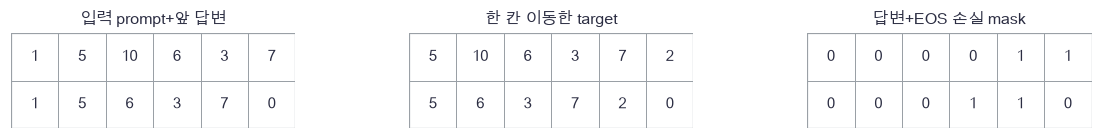

In [3]:
plot_response_mask(response_inputs_hand,response_targets_hand,response_weights_hand)

🔍 **확인** · 두 문서의 prompt 길이가 달라도 첫 답변과 EOS에1이 놓입니다. prompt 손실이0이어도 답변은 prompt를 attention으로 읽으므로 prompt의 embedding에는 미분이 갈 수 있습니다.

In [4]:
def response_batch(prompts,responses):
    """BOS·prompt·response·EOS를 이동하고 답변 첫 token부터EOS까지만 loss mask를 켭니다."""
    sequences=[[1]+list(prompt)+list(response)+[2] for prompt,response in zip(prompts,responses)]
    length=max(len(sequence)-1 for sequence in sequences)
    ids=np.zeros((len(sequences),length),dtype=int)
    targets=np.zeros_like(ids)
    valid=np.zeros_like(ids,dtype=bool)
    weights=np.zeros_like(ids,dtype=bool)
    for row,(sequence,prompt) in enumerate(zip(sequences,prompts)):
        count=len(sequence)-1
        ids[row,:count]=sequence[:-1]
        targets[row,:count]=sequence[1:]
        valid[row,:count]=True
        weights[row,len(prompt):count]=True
    return ids,targets,valid,weights

In [5]:
response_example=response_batch([[5,10,6,3],[5,6,3]],[[7],[7]])
np.testing.assert_array_equal(response_example[0],response_inputs_hand)  # 검산: 입력 shift
np.testing.assert_array_equal(response_example[1],response_targets_hand)  # 검산: 정답 shift
np.testing.assert_array_equal(response_example[3],response_weights_hand)  # 검산: prompt 길이에 맞춘 답변+EOS 선택
empty_response=response_batch([[5,3]],[[]])
assert empty_response[3].sum()==1, '빈 답변도EOS 하나를 포함합니다'
assert empty_response[1][empty_response[3]][0]==2, '빈 답변의 정답은EOS입니다'
print('첫 답변·EOS·가변 prompt·빈 답변 검산 통과')

첫 답변·EOS·가변 prompt·빈 답변 검산 통과


### ✏️ 연습 1 · 답변 mask와 valid를 합치기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

response_mask와 valid의 교집합 weights를 채우세요.

In [6]:
def exercise_responsevalid(response_mask, valid):
    """답변 mask와 valid를 합치기의 계산을 완성합니다."""
    ### 구현할 내용: response_mask와 valid의 교집합 weights를 채우세요.
    raise NotImplementedError
    return weights

In [7]:
def check_responsevalid(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.array([0,1,1],dtype=bool),np.array([1,1,0],dtype=bool)),[0,1,0])  # 검산: prompt·PAD 제외
    print("연습 1 통과")

run_check(check_responsevalid, exercise_responsevalid, hint="답변 mask와 valid를 합치기의 수식과 축을 확인하세요.")

☐ exercise_responsevalid: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 답변 mask와 valid를 합치기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
weights = response_mask & valid
```

</details>

## 🔑 2. 큰 행렬을 고정하고 작은 두 행렬을 배웁니다

**이 절에서 가져갈 것:** LoRA의 실제 행렬은 $W_0+sAB$이며, rank와 scale의 역할을 구분합니다.

기존 decoder를 전부 고치지 않고 attention의 두 행렬 Wq/Wv에만 작은 변화량을 더합니다.

$$Y=X(W_0+sAB),\quad W_0:(D,D),\quad A:(D,r),\quad B:(r,D),\quad s=\alpha/r.$$

이번 설정은 D=12,r=2,α=4이므로 s=2입니다. 행렬 하나당 학습 원소는 $2Dr=48$, 두 행렬은96개입니다. 각 변화량의 rank는 r 이하입니다. base 가중치도 저장해야 하므로 전체 모델이96개 숫자로 줄었다는 뜻은 아닙니다.

A는 작은 난수, B는0으로 시작합니다. 초기 변화량이0이므로 기존 모델 출력과 정확히 같습니다. A/B를 둘 다0으로 두면 두 미분도0이라 학습이 시작되지 않을 수 있습니다.

> **용어** · **rank**는 행렬이 표현하는 독립 방향 수입니다. 낮은 rank는 변화량의 표현 범위를 제한합니다. **scale**은 그 변화량에 곱하는 계수이며 학습률과는 별개입니다. 출처: [LoRA 원문](https://arxiv.org/abs/2106.09685).
>
> **코드** · `dict(base)`는 배열을 재사용하는 새 사전이며, 선택한 행렬에는 덧셈으로 만든 새 배열을 넣습니다. 원래 base 배열을 제자리 변경하지 않습니다.

In [8]:
lora_base_hand=np.array([[1.,0.],[0.,1.]])
lora_a_hand=np.array([[.2],[-.1]])
lora_b_hand=np.array([[.3,.4]])
lora_delta_hand=2*(lora_a_hand@lora_b_hand)
lora_effective_hand=lora_base_hand+lora_delta_hand

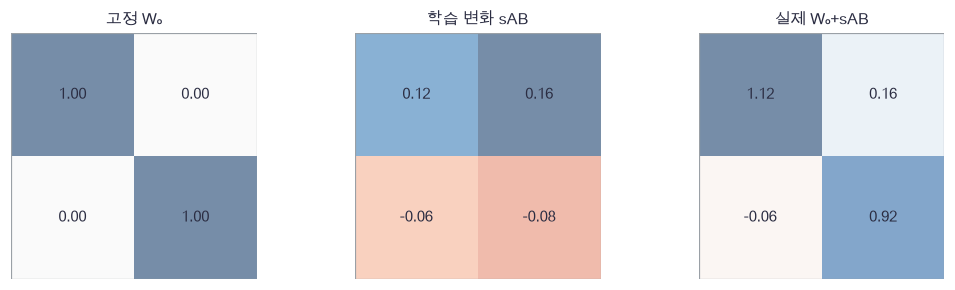

In [9]:
plot_lora_weights(lora_base_hand,lora_delta_hand,lora_effective_hand)

🔍 **확인** · 바뀌는 것은 A/B이고, forward에는 세 번째 행렬의 효과가 들어갑니다. 이 방식은 여러 파라미터를 0으로 마스킹하는 것과 다릅니다. 작은 곱이 원래 행렬의 모든 원소에 영향을 줄 수 있습니다.

In [10]:
def init_lora(base,names=('Wq','Wv'),rank=2,seed=4801):
    """A는작은난수·B는0으로 시작하여 초기 delta-W를 정확히0으로 둡니다."""
    rng=np.random.default_rng(seed)
    adapters={}
    for name in names:
        rows,columns=base[name].shape
        adapters['A_'+name]=rng.normal(0,.1,(rows,rank))
        adapters['B_'+name]=np.zeros((rank,columns))
    return adapters

In [11]:
def effective_lora(base,adapters,names=('Wq','Wv'),scale=2.):
    """고정 W0와 scale·AB를 합친 유효 파라미터 사전을 만듭니다. base는 수정하지 않습니다."""
    effective=dict(base)
    for name in names:
        effective[name]=base[name]+scale*(adapters['A_'+name]@adapters['B_'+name])
    return effective

In [12]:
hand_base={'Wq':np.eye(2),'Wv':np.eye(2)}
hand_adapters=init_lora(hand_base,rank=1)
hand_effective=effective_lora(hand_base,hand_adapters)
for name in hand_base:
    np.testing.assert_array_equal(hand_effective[name],hand_base[name])  # 검산: B=0이면초기delta=0
assert sum(value.size for value in hand_adapters.values())==8, 'D2·r1·두 행렬의 학습원소는8개입니다'
print('초기 출력 불변·adapter 원소 수 검산 통과')

초기 출력 불변·adapter 원소 수 검산 통과


### ✏️ 연습 2 · 저랭크 변화량 만들기

A,B,scale로 delta를 채우세요.

In [13]:
def exercise_delta(A, B, scale):
    """저랭크 변화량 만들기의 계산을 완성합니다."""
    ### 구현할 내용: A,B,scale로 delta를 채우세요.
    raise NotImplementedError
    return delta

In [14]:
def check_delta(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.],[2.]]),np.array([[3.,4.]]),.5),[[1.5,2.],[3.,4.]])  # 검산: rank1 외적과scale
    print("연습 2 통과")

run_check(check_delta, exercise_delta, hint="저랭크 변화량 만들기의 수식과 축을 확인하세요.")

☐ exercise_delta: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 저랭크 변화량 만들기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
delta = scale * (A @ B)
```

</details>

## 🔑 3. 고정 가중치도 입력의 미분 경로에 남습니다

**이 절에서 가져갈 것:** $W_0$를 갱신하지 않더라도 그 곱을 통한 dX를 버리면 앞쪽 adapter의 미분이 틀립니다.

출력 상류 미분 G가 주어지면 $Y=X(W_0+sAB)$에서

$$dX=G(W_0+sAB)^T,\quad H=X^TG,\quad dA=sHB^T,\quad dB=sA^TH.$$

W₀의 미분 H를 계산할 수 있지만 optimizer에 넘기지 않습니다. **미분 계산과 갱신 선택은 별개**입니다. 이번 구현은 가독성을 위해 decoder의 전체 유효 W 미분을 계산한 뒤 Wq/Wv의 H를 A/B로 전달합니다. 이 때문에 실용 라이브러리처럼 모든 임시 gradient 메모리를 절약한 구현이라고 주장하지 않습니다.

B=0이면 dA=0이고 dB는 일반적으로0이 아닙니다. B가 움직인 다음부터 A에도 학습 신호가 옵니다. 아래 그림은 고정 경로와 adapter 경로의 입력 미분을 따로 계산한 값입니다.

In [15]:
# 쓰는 것: lora_base_hand, lora_delta_hand (앞 절의 정의·실행 셀)
gradient_upstream=np.array([[1.,-2.]])
gradient_base_path=gradient_upstream@lora_base_hand.T
gradient_adapter_path=gradient_upstream@lora_delta_hand.T

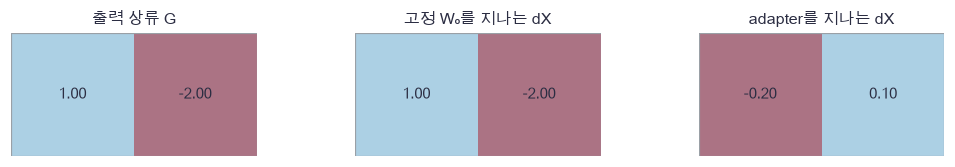

In [16]:
plot_frozen_gradient(gradient_upstream,gradient_base_path,gradient_adapter_path)

🔍 **확인** · 고정 경로의 dX도0이 아닙니다. 아래에는 이전 decoder의 전체 forward/backward·선택 CE·Adam을 독립 본문으로 다시 둡니다. causal attention·학습 위치·LN·tanh FFN·head 구조는45번과 같고, 답변 mask만 별도로 전달합니다.

> **코드** · `np.add.at`은 반복 embedding 행의 미분을 더합니다. `reshape(-1,D)`는 N,T축을 합칩니다. `numerical_gradient`는 각 파라미터를 ±h로 바꿨다가 복원합니다. `parameters.items()`는 이름과 배열을 함께 순회합니다.

In [17]:
def masked_softmax(scores, allowed):
    """마지막 key 축에서 허용한 점수만 정규화합니다. 전부 막힌 행은0입니다."""
    masked = np.where(allowed, scores, -np.inf)
    maximum = masked.max(axis=-1, keepdims=True)
    maximum = np.where(np.isfinite(maximum), maximum, 0.)
    exponential = np.exp(masked - maximum)
    total = exponential.sum(axis=-1, keepdims=True)
    return np.divide(exponential, total, out=np.zeros_like(exponential), where=total > 0)

In [18]:
def layernorm_forward(x, gamma, beta, epsilon=1e-5):
    """각 token의 마지막 D축을 정규화하고 affine 변환합니다."""
    centered = x - x.mean(axis=-1, keepdims=True)
    inverse = 1 / np.sqrt(np.mean(centered**2, axis=-1, keepdims=True) + epsilon)
    normalized = centered * inverse
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [19]:
def layernorm_backward(upstream, cache):
    """epsilon을 포함한 LayerNorm의 입력·gamma·beta 미분을 반환합니다."""
    normalized, inverse, gamma = cache
    weighted = upstream * gamma
    dx = inverse * (weighted - weighted.mean(axis=-1, keepdims=True)
                    - normalized * (weighted * normalized).mean(axis=-1, keepdims=True))
    axes = tuple(range(upstream.ndim - 1))
    return dx, np.sum(upstream * normalized, axis=axes), np.sum(upstream, axis=axes)

In [20]:
def attention_forward(x, valid, p, causal=True):
    """한 head self-attention. x:(N,T,D), valid:(N,T); query/key padding을 모두 막습니다."""
    q, k, v = x @ p['Wq'], x @ p['Wk'], x @ p['Wv']
    scores = q @ k.swapaxes(-1,-2) / np.sqrt(x.shape[-1])
    allowed = valid[:,:,None] & valid[:,None,:]
    if causal:
        allowed = allowed & np.tril(np.ones((x.shape[1],x.shape[1]),dtype=bool))[None,:,:]
    probabilities = masked_softmax(scores, allowed)
    mixed = probabilities @ v
    return mixed @ p['Wo'], (x,q,k,v,probabilities,mixed)

In [21]:
def attention_backward(upstream, cache, p):
    """attention의 값 경로와 Q/K 점수 경로를 모두 누적합니다."""
    x,q,k,v,probabilities,mixed = cache
    width = x.shape[-1]
    delta = upstream @ p['Wo'].T
    dp = delta @ v.swapaxes(-1,-2)
    dv = probabilities.swapaxes(-1,-2) @ delta
    ds = probabilities * (dp - np.sum(dp * probabilities, axis=-1, keepdims=True))
    dq = (ds @ k) / np.sqrt(width)
    dk = (ds.swapaxes(-1,-2) @ q) / np.sqrt(width)
    flat = x.reshape(-1,width)
    gradients = {'Wo': mixed.reshape(-1,width).T @ upstream.reshape(-1,width),
                 'Wq': flat.T @ dq.reshape(-1,width), 'Wk': flat.T @ dk.reshape(-1,width),
                 'Wv': flat.T @ dv.reshape(-1,width)}
    dx = dq @ p['Wq'].T + dk @ p['Wk'].T + dv @ p['Wv'].T
    return dx, gradients

In [22]:
def init_decoder(vocabulary_size, width=12, hidden=24, max_length=32, seed=45, tied=False):
    """한 pre-LN decoder block과 최종 LN·head를 만듭니다. 모든 배열은 float64입니다."""
    rng = np.random.default_rng(seed)
    p = {'E': rng.normal(0,.15,(vocabulary_size,width)),
         'P': rng.normal(0,.08,(max_length,width))}
    for layer in ['1','2','f']:
        p['g'+layer] = np.ones(width)
        p['b'+layer] = np.zeros(width)
    for name in ['Wq','Wk','Wv','Wo']:
        p[name] = rng.normal(0,.25/np.sqrt(width),(width,width))
    p['W1'] = rng.normal(0,.5/np.sqrt(width),(width,hidden))
    p['c1'] = np.zeros(hidden)
    p['W2'] = rng.normal(0,.5/np.sqrt(hidden),(hidden,width))
    p['c2'] = np.zeros(width)
    if not tied:
        p['head'] = rng.normal(0,.3/np.sqrt(width),(width,vocabulary_size))
    p['bias'] = np.zeros(vocabulary_size)
    return p

In [23]:
def decoder_from_embeddings(x, valid, p, tied=False, causal=True):
    """연속 embedding 입력에서 LN→attention→잔차→LN→FFN→잔차→LN→head입니다."""
    # 쓰는 것: layernorm_forward (앞 절의 정의·실행 셀)
    first, cache1 = layernorm_forward(x,p['g1'],p['b1'])
    attended, attention_cache = attention_forward(first,valid,p,causal)
    residual = x + attended
    second, cache2 = layernorm_forward(residual,p['g2'],p['b2'])
    activation = np.tanh(second @ p['W1'] + p['c1'])
    hidden = residual + activation @ p['W2'] + p['c2']
    final, cachef = layernorm_forward(hidden,p['gf'],p['bf'])
    head = p['E'].T if tied else p['head']
    logits = final @ head + p['bias']
    return logits,(cache1,attention_cache,cache2,second,activation,cachef,final)

In [24]:
def decoder_feature_backward(dlogits, cache, p, tied=False):
    """연속 입력과 모든 block/head 배열을 미분합니다. tied이면 출력 E 경로도 더합니다."""
    # 쓰는 것: layernorm_backward (앞 절의 정의·실행 셀)
    # 1) head와 최종 정규화를 거슬러 갑니다.
    cache1,attention_cache,cache2,second,activation,cachef,final = cache
    width = final.shape[-1]
    gradients = {name:np.zeros_like(value) for name,value in p.items()}
    head_gradient = final.reshape(-1,width).T @ dlogits.reshape(-1,dlogits.shape[-1])
    if tied:
        gradients['E'] += head_gradient.T
        delta = dlogits @ p['E']
    else:
        gradients['head'] = head_gradient
        delta = dlogits @ p['head'].T
    gradients['bias'] = dlogits.sum(axis=(0,1))
    dh,gradients['gf'],gradients['bf'] = layernorm_backward(delta,cachef)
    # 2) FFN 경로와 직접 잔차 경로를 합칩니다.
    gradients['W2'] = activation.reshape(-1,activation.shape[-1]).T @ dh.reshape(-1,width)
    gradients['c2'] = dh.sum(axis=(0,1))
    da = (dh @ p['W2'].T) * (1-activation**2)
    gradients['W1'] = second.reshape(-1,width).T @ da.reshape(-1,da.shape[-1])
    gradients['c1'] = da.sum(axis=(0,1))
    dr,gradients['g2'],gradients['b2'] = layernorm_backward(da @ p['W1'].T,cache2)
    dr += dh
    # 3) attention의 모든 경로와 첫 잔차를 합칩니다.
    du,attention_gradients = attention_backward(dr,attention_cache,p)
    gradients.update(attention_gradients)
    dx,gradients['g1'],gradients['b1'] = layernorm_backward(du,cache1)
    return dx + dr, gradients

In [25]:
def decoder_forward(ids, valid, p, tied=False, causal=True):
    """정수 ID→학습 embedding+절대 위치→decoder. PAD 위치의 입력은0으로 만듭니다."""
    assert ids.shape[1] <= len(p['P']), '학습 위치 표의 최대 길이를 넘을 수 없습니다'
    embedded = (p['E'][ids] + p['P'][:ids.shape[1]]) * valid[:,:,None]
    logits,cache = decoder_from_embeddings(embedded,valid,p,tied,causal)
    return logits,(ids,valid,cache)

In [26]:
def decoder_backward(dlogits, full_cache, p, tied=False):
    """선택된 embedding 반복행과 배치가 공유하는 위치행까지 누적합니다."""
    ids,valid,cache = full_cache
    dx,gradients = decoder_feature_backward(dlogits,cache,p,tied)
    dx *= valid[:,:,None]
    np.add.at(gradients['E'],ids.ravel(),dx.reshape(-1,dx.shape[-1]))
    gradients['P'][:ids.shape[1]] += dx.sum(axis=0)
    return gradients,dx

In [27]:
def token_cross_entropy(logits, targets, weights):
    """선택한 target만 가중 평균합니다. logprob 전체와 정확한 dlogits를 반환합니다."""
    shifted = logits - logits.max(axis=-1,keepdims=True)
    logprob = shifted - np.log(np.exp(shifted).sum(axis=-1,keepdims=True))
    denominator = weights.sum()
    assert denominator > 0, '손실에 포함할 target이 적어도 하나 필요합니다'
    assert np.all(weights >= 0), '손실 가중치는 음수가 아니어야 합니다'
    rows = np.arange(targets.size)
    selected = logprob.reshape(-1,logits.shape[-1])[rows,targets.ravel()].reshape(targets.shape)
    loss = -np.sum(selected * weights) / denominator
    delta = np.exp(logprob).reshape(-1,logits.shape[-1])
    delta[rows,targets.ravel()] -= 1
    delta *= weights.ravel()[:,None] / denominator
    return float(loss),delta.reshape(logits.shape),logprob

In [28]:
def decoder_loss(ids, targets, valid, p, tied=False, weights=None, causal=True):
    """모델 전체와 선택 target CE를 연결합니다. 입력 유효 mask와 loss mask를 구분합니다."""
    logits,cache = decoder_forward(ids,valid,p,tied,causal)
    actual_weights = valid if weights is None else weights * valid
    loss,delta,logprob = token_cross_entropy(logits,targets,actual_weights)
    gradients,dx = decoder_backward(delta,cache,p,tied)
    return loss,gradients,logprob,dx

In [29]:
def adam_state(p):
    """모든 학습 배열에 독립인 Adam 상태를 만듭니다."""
    return {'m':{name:np.zeros_like(value) for name,value in p.items()},
            'v':{name:np.zeros_like(value) for name,value in p.items()},'t':0}

In [30]:
def adam_update(p, gradients, state, learning_rate=.01):
    """Adam의 모멘트와 편향 보정으로 지정된 배열만 갱신합니다."""
    state['t'] += 1
    for name in gradients:
        state['m'][name] = .9*state['m'][name] + .1*gradients[name]
        state['v'][name] = .999*state['v'][name] + .001*gradients[name]**2
        first = state['m'][name]/(1-.9**state['t'])
        second = state['v'][name]/(1-.999**state['t'])
        p[name] -= learning_rate*first/(np.sqrt(second)+1e-8)

In [31]:
def language_batch(documents, pad=0, bos=1, eos=2):
    """정수 문서 목록을 BOS 입력·EOS 타깃으로 이동하고 오른쪽 PAD를 채웁니다."""
    length = max(len(document)+1 for document in documents)
    ids = np.full((len(documents),length),pad,dtype=int)
    targets = np.full_like(ids,pad)
    valid = np.zeros_like(ids,dtype=bool)
    for index,document in enumerate(documents):
        count = len(document)+1
        ids[index,:count] = [bos]+list(document)
        targets[index,:count] = list(document)+[eos]
        valid[index,:count] = True
    return ids,targets,valid

In [32]:
def train_decoder(train_batch, valid_batch, vocabulary_size, seed=45, steps=300, tied=False):
    """고정 300회 미니배치 Adam 후 반환합니다. valid는 기록만 하고 선택하지 않습니다."""
    # 쓰는 것: decoder_loss, init_decoder (앞 절의 정의·실행 셀)
    p = init_decoder(vocabulary_size,seed=seed,tied=tied)
    state = adam_state(p)
    rng = np.random.default_rng(seed+100)
    history = []
    for step in range(steps+1):
        if step % 100 == 0:
            train_loss = decoder_loss(*train_batch,p,tied)[0]
            valid_loss = decoder_loss(*valid_batch,p,tied)[0]
            history.append([step,train_loss,valid_loss])
        if step == steps:
            break
        index = rng.integers(0,len(train_batch[0]),size=8)
        batch = tuple(array[index] for array in train_batch)
        _,gradients,_,_ = decoder_loss(*batch,p,tied)
        adam_update(p,gradients,state)
    return p,np.asarray(history)

In [33]:
def greedy_decode(prefix, p, eos=2, max_new_tokens=30, tied=False):
    """prefix를 유지하고 전체 문맥을 매번 재계산해 EOS 또는 길이 상한까지 생성합니다."""
    # 쓰는 것: decoder_forward (앞 절의 정의·실행 셀)
    tokens = list(prefix)
    assert len(tokens)>0, 'prefix에는 BOS 등 적어도 한 token이 필요합니다'
    for _ in range(max_new_tokens):
        if len(tokens) >= len(p['P']):
            break
        ids = np.array([tokens],dtype=int)
        logits,_ = decoder_forward(ids,np.ones_like(ids,dtype=bool),p,tied)
        scores = logits[0,-1].copy()
        scores[[0,1]] = -np.inf
        token = int(np.argmax(scores))
        tokens.append(token)
        if token==eos:
            break
    return tokens,bool(tokens[-1]==eos)

In [34]:
def lora_loss(batch,base,adapters,names=('Wq','Wv'),scale=2.):
    """고정 decoder 전체를 통해 미분하고 선택 W의 기여를 A/B로 전달합니다."""
    # 쓰는 것: decoder_loss, effective_lora (앞 절의 정의·실행 셀)
    effective=effective_lora(base,adapters,names,scale)
    ids,targets,valid,weights=batch
    loss,base_gradients,logprob,dx=decoder_loss(ids,targets,valid,effective,weights=weights)
    gradients={}
    for name in names:
        weight_gradient=base_gradients[name]
        gradients['A_'+name]=scale*weight_gradient@adapters['B_'+name].T
        gradients['B_'+name]=scale*adapters['A_'+name].T@weight_gradient
    return loss,gradients,logprob,dx

In [35]:
def response_metrics(batch,p):
    """답변+EOS의 teacher-forced NLL·token 정확도입니다. prompt 손실은 제외합니다."""
    # 쓰는 것: decoder_loss (앞 절의 정의·실행 셀)
    ids,targets,valid,weights=batch
    loss,_,logprob,_=decoder_loss(ids,targets,valid,p,weights=weights)
    accuracy=np.sum((logprob.argmax(axis=-1)==targets)*weights)/weights.sum()
    return loss,float(accuracy)

In [36]:
def check_lora_gradients():
    """B=0 초기경계와 비영 A/B의 모든 원소를 전체 decoder 안에서 검산합니다."""
    # 쓰는 것: decoder_forward, effective_lora, init_decoder, init_lora, response_batch, token_cross_entropy (앞 절의 정의·실행 셀)
    base=init_decoder(8,width=3,hidden=4,max_length=6,seed=4803)
    batch=response_batch([[4,6,3],[4,7,3]],[[7],[6]])
    adapters=init_lora(base,rank=2)
    _,initial_gradients,_,dx=lora_loss(batch,base,adapters)
    for name in ['Wq','Wv']:
        assert np.all(initial_gradients['A_'+name]==0), 'B=0일 때 A미분은0입니다'
    assert np.max(np.abs(initial_gradients['B_Wv']))>1e-8, '이 고정 예에서 B에는 학습 신호가 있어야 합니다'
    rng=np.random.default_rng(4804)
    for name in adapters:
        adapters[name]+=rng.normal(0,.05,adapters[name].shape)
    _,gradients,_,dx=lora_loss(batch,base,adapters)
    def objective():
        """고정 base·prompt·답변의 LoRA 손실입니다."""
        return lora_loss(batch,base,adapters)[0]
    errors=[]
    for name,value in adapters.items():
        numeric=numerical_gradient(objective,value)
        np.testing.assert_allclose(gradients[name],numeric,atol=3e-7,rtol=2e-4)  # 검산: 모든 A/B 원소 손미분 = 중심차분
        errors.append(np.max(np.abs(gradients[name]-numeric)))
    assert np.max(np.abs(dx[:,1]))>1e-8, 'prompt는 손실0이어도 답변의 문맥 미분을 받습니다'
    effective=effective_lora(base,adapters)
    logits,_=decoder_forward(batch[0],batch[2],effective)
    _,delta,_=token_cross_entropy(logits,batch[1],batch[3])
    assert np.all(delta[~batch[3]]==0), 'prompt/PAD의 직접 logits 미분은0입니다'
    return max(errors)

In [37]:
print('전체 decoder를 통과한 A/B 전수 미분 최대오차:',check_lora_gradients())

전체 decoder를 통과한 A/B 전수 미분 최대오차: 2.9742160286266167e-10


### ✏️ 연습 3 · B의 기울기 계산하기

A와 유효 행렬 미분 H에서 dB를 채우세요.

In [38]:
def exercise_db(A, H, scale):
    """B의 기울기 계산하기의 계산을 완성합니다."""
    ### 구현할 내용: A와 유효 행렬 미분 H에서 dB를 채우세요.
    raise NotImplementedError
    return dB

In [39]:
def check_db(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.],[2.]]),np.eye(2),2.),[[2.,4.]])  # 검산: scale AᵀH
    print("연습 3 통과")

run_check(check_db, exercise_db, hint="B의 기울기 계산하기의 수식과 축을 확인하세요.")

☐ exercise_db: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: B의 기울기 계산하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dB = scale * (A.T @ H)
```

</details>

## 🔑 4. 같은 base에서 full·frozen·LoRA를 비교합니다

**이 절에서 가져갈 것:** 학습 파라미터 수와 실제 갱신 횟수를 세고, 새 과제와 기존 과제를 함께 평가합니다.

색ID6–9는 네 색을 순서대로 나타내고 과일은10–13입니다. 기존 COPY 과제는 `[COPY,fruit,color,SEP]→color,EOS`, 새 NEXT 과제는 색을 한 칸 순환한 `6+(color-6+1)%4`를 답합니다. 같은 입력 색에 다른 행동을 원하므로 task token도 COPY=4와 NEXT=5로 구분합니다.

색×과일16개를 seed4800으로 train12/valid2/test2로 나눕니다. 먼저 COPY의 전체 next-token CE로200회 학습합니다. 이후 **동일 base**에서 NEXT의 response-only CE로300회 적응합니다. full과LoRA는 같은 배치 순서·배치8·Adam.01을 쓰고, frozen은0회 갱신하는 대조입니다. valid는 기록만 하며 test로 설정을 고르지 않습니다.

D=12,F=24,V=14,Tmax=32일 때 base는1,994개입니다. full은1,994개, LoRA는96개, frozen은0개를 갱신합니다. 아래는 함수가 실제 만든 배열을 세어 확인한 값입니다.

In [40]:
# 쓰는 것: init_decoder, init_lora (앞 절의 정의·실행 셀)
budget_base=init_decoder(14,seed=48)
budget_adapters=init_lora(budget_base)
trainable_counts=np.array([0,sum(value.size for value in budget_base.values()),sum(value.size for value in budget_adapters.values())])

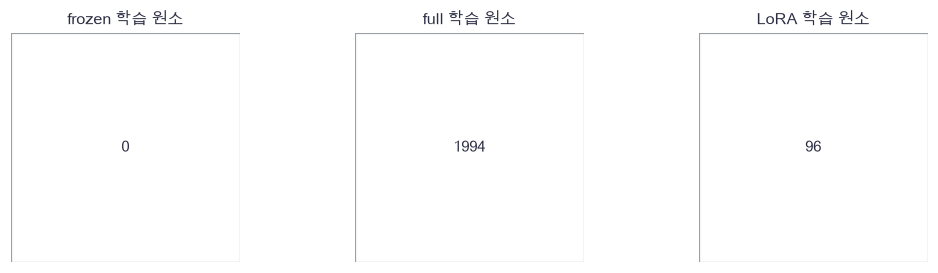

In [41]:
plot_trainable_budget(trainable_counts,['frozen','full','LoRA'])

🔍 **확인** · LoRA에도 base1,994개를 저장하고 forward에 사용합니다. 학습 배열과 Adam 상태만 작습니다. 두 적응 방법의 표현력·연산량까지 동일한 대조는 아닙니다. 작은 두 문장 test와 한 seed의 결과를 보편적 우승 방법으로 읽지 않습니다.

> **코드** · 사전 컴프리헨션의 `.copy()`는 방법별 학습이 같은 base를 훼손하지 않게 합니다. `state['t']`는 실제 optimizer 갱신 횟수입니다. `mode=='frozen'`의 곡선 가로축은 예정 번호이며 실제 갱신은0입니다.

In [42]:
def adapt_model(base,train_batch,valid_batch,mode,steps=300):
    """full·frozen·LoRA를 같은 답변목적/배치순서로 비교하며 valid로 설정을 고르지 않습니다."""
    # 쓰는 것: adam_state, adam_update, decoder_loss, effective_lora, init_lora, lora_loss, response_metrics (앞 절의 정의·실행 셀)
    p={name:value.copy() for name,value in base.items()}
    adapters=init_lora(base)
    active=adapters if mode=='LoRA' else p
    state=adam_state(active)
    rng=np.random.default_rng(4802)
    history=[]
    for step in range(steps+1):
        effective=effective_lora(base,adapters) if mode=='LoRA' else p
        if step%100==0:
            history.append([step,response_metrics(train_batch,effective)[0],response_metrics(valid_batch,effective)[0]])
        if step==steps:
            break
        if mode=='frozen':
            continue
        index=rng.integers(0,len(train_batch[0]),size=8)
        batch=tuple(array[index] for array in train_batch)
        if mode=='LoRA':
            _,gradients,_,_=lora_loss(batch,base,adapters)
        else:
            ids,targets,valid,weights=batch
            _,gradients,_,_=decoder_loss(ids,targets,valid,p,weights=weights)
        adam_update(active,gradients,state)
    effective=effective_lora(base,adapters) if mode=='LoRA' else p
    learned=sum(value.size for value in active.values()) if mode!='frozen' else 0
    return effective,np.asarray(history),adapters,learned,state['t']

In [43]:
pairs=[(fruit,color) for fruit in range(10,14) for color in range(6,10)]
order=np.random.default_rng(4800).permutation(16)
train_pairs=[pairs[i] for i in order[:12]]
valid_pairs=[pairs[i] for i in order[12:14]]
test_pairs=[pairs[i] for i in order[14:]]
assert not set(train_pairs)&set(test_pairs), 'train/test의 조합은 겹치면 안 됩니다'

In [44]:
def make_task_batch(pairs,copy_task):
    """과일·색 조합을 COPY 또는NEXT 지시의 prompt/답변 배열로 만듭니다."""
    # 쓰는 것: response_batch (앞 절의 정의·실행 셀)
    prompts=[[4 if copy_task else 5,fruit,color,3] for fruit,color in pairs]
    responses=[[color if copy_task else 6+(color-6+1)%4] for fruit,color in pairs]
    return response_batch(prompts,responses)

In [45]:
# 쓰는 것: train_decoder (앞 절의 정의·실행 셀)
copy_train,copy_valid,copy_test=[make_task_batch(part,True) for part in [train_pairs,valid_pairs,test_pairs]]
sft_train,sft_valid,sft_test=[make_task_batch(part,False) for part in [train_pairs,valid_pairs,test_pairs]]
base,base_history=train_decoder(copy_train[:3],copy_valid[:3],14,seed=48,steps=200)
base_snapshot={name:value.copy() for name,value in base.items()}
methods=['frozen','full','LoRA']
adapted_models,adaptation_histories,adapter_results,update_counts={},{},{},{}
for method in methods:
    effective,history,adapters,learned,updates=adapt_model(base,sft_train,sft_valid,method)
    adapted_models[method]=effective
    adaptation_histories[method]=history
    adapter_results[method]=adapters
    update_counts[method]=updates
    print(method,'학습 원소',learned,'· 실제 갱신',updates)
for name in base:
    np.testing.assert_array_equal(base[name],base_snapshot[name])  # 검산: 방법별 학습 뒤에도 공통base 보존

frozen 학습 원소 0 · 실제 갱신 0


full 학습 원소 1994 · 실제 갱신 300
LoRA 학습 원소 96 · 실제 갱신 300


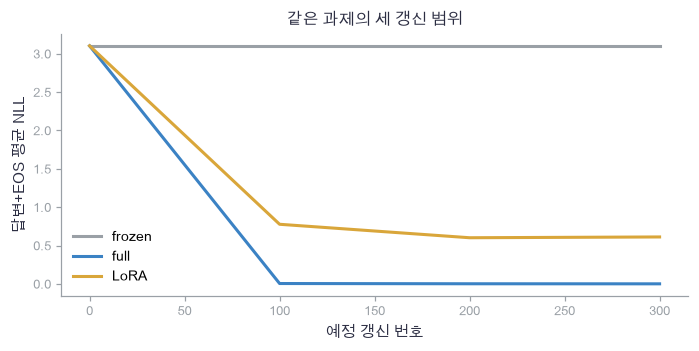

In [46]:
plot_adaptation_learning([adaptation_histories[method] for method in methods],methods)

In [47]:
# 쓰는 것: response_metrics (앞 절의 정의·실행 셀)
for method in methods:
    model=adapted_models[method]
    print(method,'NEXT test [NLL, token정확도]:',response_metrics(sft_test,model),
          '· 기존 COPY test:',response_metrics(copy_test,model))
assert update_counts['frozen']==0, 'frozen은 실제갱신0입니다'
assert update_counts['full']==300, 'full은300번 갱신합니다'
assert update_counts['LoRA']==300, 'LoRA도300번 갱신합니다'

frozen NEXT test [NLL, token정확도]: (3.1244859701474996, 0.5) · 기존 COPY test: (0.012814514738581842, 1.0)
full NEXT test [NLL, token정확도]: (0.0008709767210820644, 1.0) · 기존 COPY test: (4.037058512028277, 0.5)
LoRA NEXT test [NLL, token정확도]: (1.0431251534690487, 0.75) · 기존 COPY test: (1.0675288051580176, 0.5)


🔍 **확인** · 이 고정 실험에서 full과LoRA의 새 과제 정확도나 기존 과제 유지가 같을 필요는 없습니다. 큰 새 과제 개선과 기존 과제 성능 저하가 동시에 나타날 수 있습니다. 답변 token과EOS를 함께 평균하므로 색 token 하나의 정확도나 답변 전체 일치는 다음 생성 결과로도 확인합니다.

### ✏️ 연습 4 · 학습할 원소 수 세기

arrays에 들어 있는 학습 배열 원소 합 count를 채우세요.

In [48]:
def exercise_count(arrays):
    """학습할 원소 수 세기의 계산을 완성합니다."""
    ### 구현할 내용: arrays에 들어 있는 학습 배열 원소 합 count를 채우세요.
    raise NotImplementedError
    return count

In [49]:
def check_count(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([np.zeros((3,2)),np.zeros((2,4))])==14, 'A6개+B8개=14입니다'
    print("연습 4 통과")

run_check(check_count, exercise_count, hint="학습할 원소 수 세기의 수식과 축을 확인하세요.")

☐ exercise_count: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 학습할 원소 수 세기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
count = sum(value.size for value in arrays)
```

</details>

## 🔑 5. merge의 동등성과 정답 없는 답변을 확인합니다

**이 절에서 가져갈 것:** 고정 가중치에 delta를 합친 모델은 같은 logits를 내야 하며, 실제 답변은 prompt만으로 생성합니다.

학습을 마친 A/B를 매번 곱하지 않고 사본 $W_{merged}=W_0+sAB$에 합칠 수 있습니다. 같은 scale·같은 가중치라면 유효 W가 같으므로 logits도 같습니다. base와adapter 원본을 보존해 두어야 다른 방법과 비교하거나 원래 모델로 돌아갈 수 있습니다.

아래 그림은 실제 LoRA 모델과 직접 합친 사본의 test logits 중 첫 문서·마지막 두 위치·앞 네 어휘만 표시합니다. 검산은 잘라낸 부분만이 아니라 전체 logits에서 수행합니다.

In [50]:
# 쓰는 것: adapted_models, adapter_results, base, decoder_forward, sft_test (앞 절의 정의·실행 셀)
merge_preview={name:value.copy() for name,value in base.items()}
for name in ['Wq','Wv']:
    merge_preview[name]+=2*(adapter_results['LoRA']['A_'+name]@adapter_results['LoRA']['B_'+name])
unmerged_logits,_=decoder_forward(sft_test[0],sft_test[2],adapted_models['LoRA'])
merged_logits,_=decoder_forward(sft_test[0],sft_test[2],merge_preview)
merge_difference=unmerged_logits-merged_logits

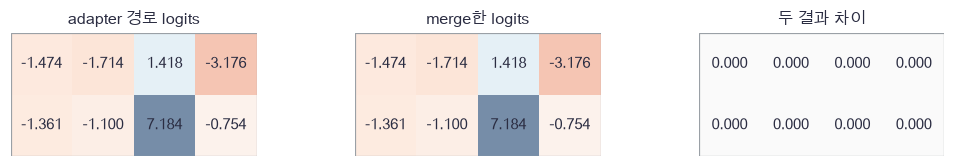

In [51]:
plot_merge_logits(unmerged_logits[0,-2:,:4],merged_logits[0,-2:,:4],merge_difference[0,-2:,:4])

🔍 **확인** · 오른쪽 차이는0에 가깝습니다. merge는 생성 품질을 높이는 새로운 학습이 아니라 같은 유효 행렬을 저장하는 방식입니다. adapter를 더한 상태에 같은delta를 다시 더하면 다른 모델이 되므로 base의 사본에서 한 번만 합칩니다.

In [52]:
def merge_lora(base,adapters,names=('Wq','Wv'),scale=2.):
    """별도 사본에 delta-W를 합쳐 추론용으로 만듭니다. adapter와 base 원본은 보존합니다."""
    merged={name:value.copy() for name,value in base.items()}
    for name in names:
        merged[name]+=scale*(adapters['A_'+name]@adapters['B_'+name])
    return merged

In [53]:
# 쓰는 것: adapted_models, adapter_results, base, base_snapshot, decoder_forward, greedy_decode, methods, sft_test, test_pairs (앞 절의 정의·실행 셀)
merged=merge_lora(base,adapter_results['LoRA'])
np.testing.assert_allclose(decoder_forward(sft_test[0],sft_test[2],merged)[0],unmerged_logits,atol=1e-12)  # 검산: 전체 logits merge 동등성
for method in methods:
    for fruit,color in test_pairs:
        prompt=[1,5,fruit,color,3]
        generated,stopped=greedy_decode(prompt,adapted_models[method],max_new_tokens=3)
        response=generated[len(prompt):]
        expected=[6+(color-6+1)%4,2]
        print(method,'prompt',prompt,'· 답변',response,'· 정답',expected,'· EOS',stopped,'· 전체일치',response==expected)
for name in base:
    np.testing.assert_array_equal(base[name],base_snapshot[name])  # 검산: merge·생성 뒤에도base 보존
print('전체 merge 동등성·고정base·정답 없는 답변 실행 완료')

frozen prompt [1, 5, 11, 9, 3] · 답변 [9, 2] · 정답 [6, 2] · EOS True · 전체일치 False
frozen prompt [1, 5, 13, 6, 3] · 답변 [6, 2] · 정답 [7, 2] · EOS True · 전체일치 False
full prompt [1, 5, 11, 9, 3] · 답변 [6, 2] · 정답 [6, 2] · EOS True · 전체일치 True
full prompt [1, 5, 13, 6, 3] · 답변 [7, 2] · 정답 [7, 2] · EOS True · 전체일치 True
LoRA prompt [1, 5, 11, 9, 3] · 답변 [6, 2] · 정답 [6, 2] · EOS True · 전체일치 True
LoRA prompt [1, 5, 13, 6, 3] · 답변 [6, 2] · 정답 [7, 2] · EOS True · 전체일치 False
전체 merge 동등성·고정base·정답 없는 답변 실행 완료


📎 **참고** · SFT의 시범 답변 학습은 [Ouyang 외 원문](https://arxiv.org/abs/2203.02155)의 학습 단계와 연결됩니다. 여기서는 사람 피드백·reward 모델·RL을 실행한 것이 아니라 합성 지시의 지도학습만 수행했습니다. [LoRA 원문](https://arxiv.org/abs/2106.09685)의 저랭크 적응을 작은 attention 행렬에 옮겼으며 원 논문의 성능·메모리 절감 비율을 재현한다고 주장하지 않습니다.

구조는 작은 decoder, 목적은 답변 CE, 갱신 범위는 full/frozen/A·B, 사용은 prompt만 주는 생성입니다. 다음49번은 정답 답변 하나 대신 두 답변의 선호로 목적을 바꿉니다.

### ✏️ 연습 5 · base 사본에 delta를 합치기

base와 delta를 더한 merged를 만드세요. 원본은 바꾸지 마세요.

In [54]:
def exercise_merge(base, delta):
    """base 사본에 delta를 합치기의 계산을 완성합니다."""
    ### 구현할 내용: base와 delta를 더한 merged를 만드세요. 원본은 바꾸지 마세요.
    raise NotImplementedError
    return merged

In [55]:
def check_merge(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    base=np.array([[1.,0.]])
    np.testing.assert_allclose(candidate(base,np.array([[.2,.3]])),[[1.2,.3]])  # 검산: 합친값
    np.testing.assert_array_equal(base,[[1.,0.]])  # 검산: 원본보존
    print("연습 5 통과")

run_check(check_merge, exercise_merge, hint="base 사본에 delta를 합치기의 수식과 축을 확인하세요.")

☐ exercise_merge: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: base 사본에 delta를 합치기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
merged = base + delta
```

</details>

## ✏️ 끝 연습 · A–D

초기화·미분·분모·동등성을 다시 확인합니다.

### ✏️ 연습 A · scale 계산하기

alpha와 rank로 scale을 구하세요.

In [56]:
def exercise_scale(alpha, rank):
    """scale 계산하기의 계산을 완성합니다."""
    ### 구현할 내용: alpha와 rank로 scale을 구하세요.
    raise NotImplementedError
    return scale

In [57]:
def check_scale(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(4,2)==2, 'scale은alpha/r입니다'
    print("연습 A 통과")

run_check(check_scale, exercise_scale, hint="scale 계산하기의 수식과 축을 확인하세요.")

☐ exercise_scale: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: scale 계산하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
scale = alpha / rank
```

</details>

### ✏️ 연습 B · A의 기울기 계산하기

유효 W 미분 H와 B에서 dA를 구하세요.

In [58]:
def exercise_da(H, B, scale):
    """A의 기울기 계산하기의 계산을 완성합니다."""
    ### 구현할 내용: 유효 W 미분 H와 B에서 dA를 구하세요.
    raise NotImplementedError
    return dA

In [59]:
def check_da(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.eye(2),np.array([[3.,4.]]),2.),[[6.],[8.]])  # 검산: scale HBᵀ
    print("연습 B 통과")

run_check(check_da, exercise_da, hint="A의 기울기 계산하기의 수식과 축을 확인하세요.")

☐ exercise_da: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: A의 기울기 계산하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dA = scale * H @ B.T
```

</details>

### ✏️ 연습 C · frozen 입력 경로 유지하기

상류 G와 고정W0·delta를 사용해 dx를 채우세요.

In [60]:
def exercise_frozenpath(G, W0, delta):
    """frozen 입력 경로 유지하기의 계산을 완성합니다."""
    ### 구현할 내용: 상류 G와 고정W0·delta를 사용해 dx를 채우세요.
    raise NotImplementedError
    return dx

In [61]:
def check_frozenpath(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,2.]]),np.eye(2),np.zeros((2,2))),[[1.,2.]])  # 검산: delta0이어도고정경로존재
    print("연습 C 통과")

run_check(check_frozenpath, exercise_frozenpath, hint="frozen 입력 경로 유지하기의 수식과 축을 확인하세요.")

☐ exercise_frozenpath: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: frozen 입력 경로 유지하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dx = G @ (W0 + delta).T
```

</details>

### ✏️ 연습 D · 답변 손실만 평균하기

token_nll과 weights에서 loss를 구하세요.

In [62]:
def exercise_answermean(token_nll, weights):
    """답변 손실만 평균하기의 계산을 완성합니다."""
    ### 구현할 내용: token_nll과 weights에서 loss를 구하세요.
    raise NotImplementedError
    return loss

In [63]:
def check_answermean(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(np.array([100.,2.,4.]),np.array([0,1,1]))==3, 'prompt100은제외하고답변2개평균입니다'
    print("연습 D 통과")

run_check(check_answermean, exercise_answermean, hint="답변 손실만 평균하기의 수식과 축을 확인하세요.")

☐ exercise_answermean: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 답변 손실만 평균하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = np.sum(token_nll * weights) / weights.sum()
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

- **설명:** prompt 손실이0인데 prompt embedding에 미분이 갈 수 있는 이유를 말할 수 있나요?
- **수식:** $W_0+sAB$의 dX,dA,dB를 유도하고 B=0에서 초기 두 미분의 차이를 설명할 수 있나요?
- **구현:** base 전체를 통과해 A/B만 갱신하고 base 불변·학습 원소 수·실제 optimizer 시계를 검산할 수 있나요?
- **변형 검산:** prompt 길이·빈 답변·rank·scale·merge 전후·기존 과제를 바꾸어 보존되는 값과 바뀌는 값을 구분할 수 있나요?